In [1]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

if tf.config.list_physical_devices('GPU'):
    print("GPU is ready!")
else:
    print("GPU not available. Check runtime settings.")

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is ready!


In [2]:
!pip install --upgrade -q kaggle

In [3]:
import os
import getpass

token = getpass.getpass("Enter your Kaggle API token: ")

os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle token configured!")

Enter your Kaggle API token: ··········
Kaggle token configured!


In [4]:
!kaggle datasets list -s "chest xray pneumonia"

ref                                                             title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
divyam6969/chest-xray-pneumonia-dataset                         Chest XRAY - Pneumonia Dataset                       1151535496  2024-01-17 12:19:16.570000           1577         30  0.6875           
kostasdiamantaras/chest-xrays-bacterial-viral-pneumonia-normal  Chest Xrays: bacterial / viral pneumonia / normal    1222999548  2020-10-27 16:51:15.783000           6335         22  0.7058824        
amanullahasraf/covid19-pneumonia-normal-chest-xray-pa-dataset   COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset       2053474983  2020-07-13 05:54:22.483000           4466         36  0.8125       

In [5]:
!mkdir -p /content/chest_xray_data

!kaggle datasets download \
    -d paultimothymooney/chest-xray-pneumonia \
    -p /content/chest_xray_data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:16<00:00, 154MB/s]



In [6]:
import os

DATASET_PATH = "/content/chest_xray_data/chest_xray"

print("Dataset folders:")

for folder in os.listdir(DATASET_PATH):
    print(folder, "->", os.listdir(
        os.path.join(DATASET_PATH, folder)
    ))

Dataset folders:
test -> ['NORMAL', 'PNEUMONIA']
chest_xray -> ['test', '.DS_Store', 'val', 'train']
__MACOSX -> ['chest_xray', '._chest_xray']
val -> ['NORMAL', 'PNEUMONIA']
train -> ['NORMAL', 'PNEUMONIA']


In [7]:
import os

DATASET_PATH = "/content/chest_xray_data/chest_xray"

splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]

for split in splits:
    print(f"\n{split.upper()} DATASET")

    for class_name in classes:
        folder = os.path.join(DATASET_PATH, split, class_name)

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{class_name}: {len(images)} images")


TRAIN DATASET
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL DATASET
NORMAL: 8 images
PNEUMONIA: 8 images

TEST DATASET
NORMAL: 234 images
PNEUMONIA: 390 images


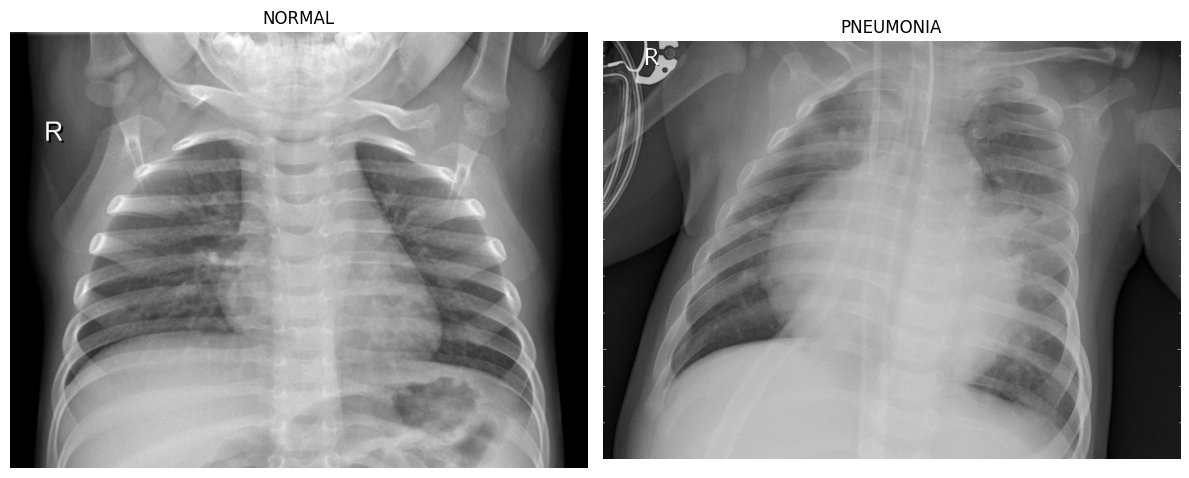

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import random

plt.figure(figsize=(12, 6))

for i, class_name in enumerate(["NORMAL", "PNEUMONIA"]):
    folder = os.path.join(DATASET_PATH, "train", class_name)

    image_name = random.choice(os.listdir(folder))
    image_path = os.path.join(folder, image_name)

    image = mpimg.imread(image_path)

    plt.subplot(1, 2, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

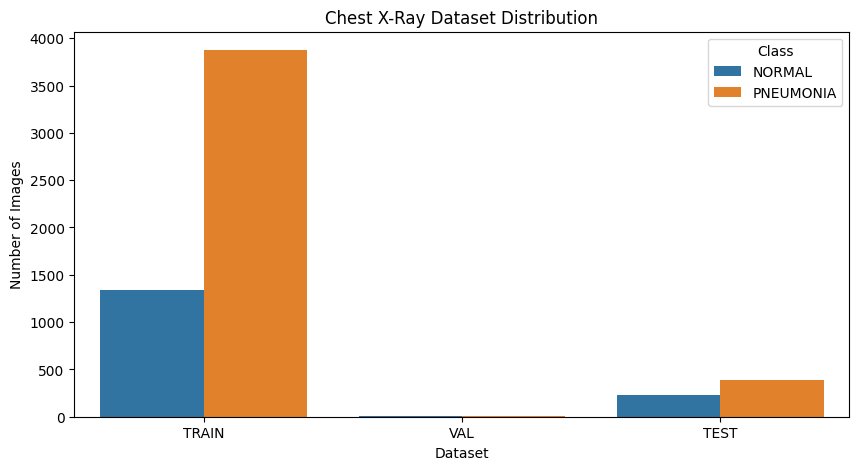

,Dataset,Class,Count
0,TRAIN,NORMAL,1341
1,TRAIN,PNEUMONIA,3875
2,VAL,NORMAL,8
3,VAL,PNEUMONIA,8
4,TEST,NORMAL,234
5,TEST,PNEUMONIA,390


In [9]:
import pandas as pd
import seaborn as sns

data = []

for split in splits:
    for class_name in classes:
        folder = os.path.join(DATASET_PATH, split, class_name)

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        data.append({
            "Dataset": split.upper(),
            "Class": class_name,
            "Count": count
        })

df = pd.DataFrame(data)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Dataset", y="Count", hue="Class")

plt.title("Chest X-Ray Dataset Distribution")
plt.ylabel("Number of Images")
plt.show()

display(df)

In [10]:
from PIL import Image
import os
import pandas as pd

image_details = []

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:

        folder = os.path.join(DATASET_PATH, split, class_name)

        for filename in os.listdir(folder):

            if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                image_path = os.path.join(folder, filename)

                with Image.open(image_path) as img:
                    width, height = img.size

                image_details.append({
                    "Split": split,
                    "Class": class_name,
                    "Filename": filename,
                    "Width": width,
                    "Height": height,
                    "Format": img.format
                })

image_df = pd.DataFrame(image_details)

print("Total Images:", len(image_df))
display(image_df.head(10))

Total Images: 5856


,Split,Class,Filename,Width,Height,Format
0,train,NORMAL,IM-0746-0001.jpeg,1712,1259,JPEG
1,train,NORMAL,NORMAL2-IM-0499-0001.jpeg,1414,1106,JPEG
2,train,NORMAL,NORMAL2-IM-0818-0001-0002.jpeg,1679,1914,JPEG
3,train,NORMAL,IM-0275-0001.jpeg,1866,1595,JPEG
4,train,NORMAL,IM-0523-0001-0002.jpeg,1762,1480,JPEG
5,train,NORMAL,NORMAL2-IM-0671-0001.jpeg,1546,1205,JPEG
6,train,NORMAL,IM-0307-0001.jpeg,1766,1557,JPEG
7,train,NORMAL,NORMAL2-IM-0971-0001-0001.jpeg,1850,1785,JPEG
8,train,NORMAL,NORMAL2-IM-0485-0001.jpeg,1120,904,JPEG
9,train,NORMAL,NORMAL2-IM-0797-0001.jpeg,1612,1515,JPEG


In [11]:
print("IMAGE DIMENSION STATISTICS")

print("\nWidth Statistics:")
print(image_df["Width"].describe())

print("\nHeight Statistics:")
print(image_df["Height"].describe())

print("\nImage Format Distribution:")
print(image_df["Format"].value_counts())

IMAGE DIMENSION STATISTICS

Width Statistics:
count    5856.000000
mean     1327.880806
std       363.500922
min       384.000000
25%      1056.000000
50%      1281.000000
75%      1560.000000
max      2916.000000
Name: Width, dtype: float64

Height Statistics:
count    5856.000000
mean      970.689037
std       383.392117
min       127.000000
25%       688.000000
50%       888.000000
75%      1187.000000
max      2713.000000
Name: Height, dtype: float64

Image Format Distribution:
Format
JPEG    5856
Name: count, dtype: int64


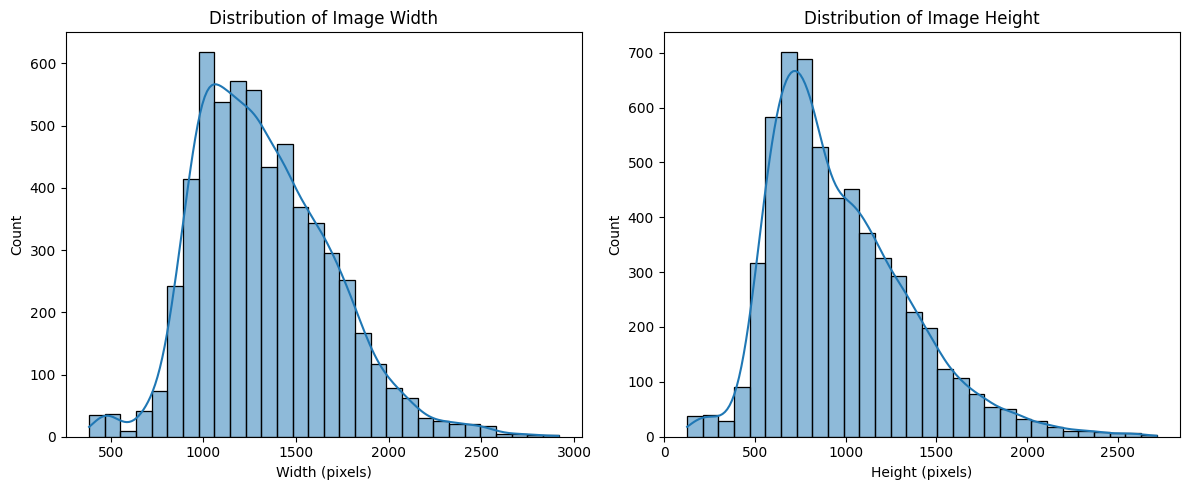

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(image_df["Width"], bins=30, kde=True)
plt.title("Distribution of Image Width")
plt.xlabel("Width (pixels)")

plt.subplot(1, 2, 2)
sns.histplot(image_df["Height"], bins=30, kde=True)
plt.title("Distribution of Image Height")
plt.xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

   Split      Class  Image_Count
0   test     NORMAL          234
1   test  PNEUMONIA          390
2  train     NORMAL         1341
3  train  PNEUMONIA         3875
4    val     NORMAL            8
5    val  PNEUMONIA            8


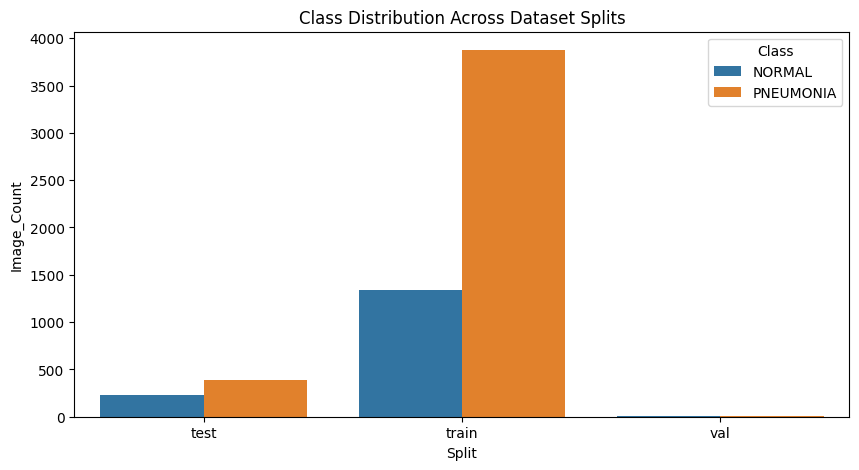

In [13]:
class_distribution = (
    image_df.groupby(["Split", "Class"])
    .size()
    .reset_index(name="Image_Count")
)

print(class_distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution,
    x="Split",
    y="Image_Count",
    hue="Class"
)

plt.title("Class Distribution Across Dataset Splits")
plt.show()

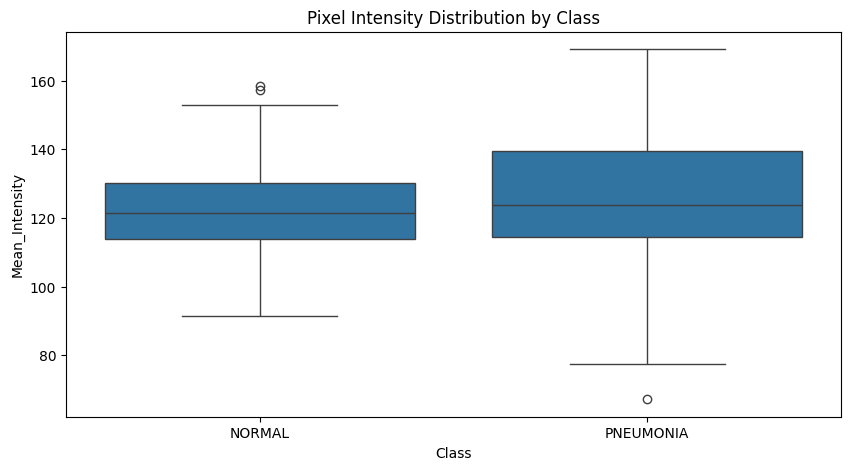

,Mean_Intensity,Std_Intensity
Class,,
NORMAL,121.957893,60.748913
PNEUMONIA,124.690792,57.371719


In [14]:
import numpy as np
from PIL import Image

pixel_means = []

for class_name in ["NORMAL", "PNEUMONIA"]:

    folder = os.path.join(DATASET_PATH, "train", class_name)

    sample_images = os.listdir(folder)[:100]

    for filename in sample_images:

        image_path = os.path.join(folder, filename)

        img = Image.open(image_path).convert("L")
        img_array = np.array(img)

        pixel_means.append({
            "Class": class_name,
            "Mean_Intensity": img_array.mean(),
            "Std_Intensity": img_array.std()
        })

pixel_df = pd.DataFrame(pixel_means)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=pixel_df,
    x="Class",
    y="Mean_Intensity"
)

plt.title("Pixel Intensity Distribution by Class")
plt.show()

display(pixel_df.groupby("Class").mean(numeric_only=True))

In [15]:
from PIL import Image
import os

corrupted_images = []

for split in ["train", "val", "test"]:
    for class_name in ["NORMAL", "PNEUMONIA"]:

        folder = os.path.join(DATASET_PATH, split, class_name)

        for filename in os.listdir(folder):

            if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            image_path = os.path.join(folder, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(image_path)

print("Corrupted Images:", len(corrupted_images))

if len(corrupted_images) == 0:
    print("All checked images are valid!")
else:
    print("Corrupted image paths:")
    print(corrupted_images[:10])

Corrupted Images: 0
All checked images are valid!


In [16]:
IMG_SIZE = (224, 224)

print("Target Image Size:", IMG_SIZE)

Target Image Size: (224, 224)


In [17]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

print("Class Names:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Class Names: ['NORMAL', 'PNEUMONIA']


In [18]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/train",
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/train",
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb"
)

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.


In [19]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def preprocess_images(images, labels):
    images = preprocess_input(images)
    return images, labels

train_ds = train_ds.map(preprocess_images)
val_ds = val_ds.map(preprocess_images)
test_ds = test_ds.map(preprocess_images)

In [20]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


In [20]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

test_ds = test_ds.cache().prefetch(
    buffer_size=AUTOTUNE
)

print("Dataset pipelines optimized!")

In [21]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05)
])

# Load the pre-trained MobileNetV2 model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pre-trained layers
base_model.trainable = False

# Build the complete classification model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

# Display model architecture
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [22]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [23]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 44s 231ms/step - accuracy: 0.6723 - auc: 0.4969 - loss: 0.6384 - precision: 0.7404 - recall: 0.8584 - val_accuracy: 0.7570 - val_auc: 0.7419 - val_loss: 0.5507 - val_precision: 0.7570 - val_recall: 1.0000
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 33s 221ms/step - accuracy: 0.7271 - auc: 0.5250 - loss: 0.5958 - precision: 0.7420 - recall: 0.9680 - val_accuracy: 0.7570 - val_auc: 0.9127 - val_loss: 0.5434 - val_precision: 0.7570 - val_recall: 1.0000
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 31s 219ms/step - accuracy: 0.7278 - auc: 0.5407 - loss: 0.5904 - precision: 0.7406 - recall: 0.9732 - val_accuracy: 0.7570 - val_auc: 0.9254 - val_loss: 0.5359 - val_precision: 0.7570 - val_recall: 1.0000
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 30s 217ms/step - accuracy: 0.7359 - auc: 0.5693 - loss: 0.5762 - precision: 0.7444 - recall: 0.9796 - val_accuracy: 0.7570 - val_auc: 0.9226 - val_loss: 0.5284 - val_precision: 0.7570 - val_recall: 1.0000
Epoch 5/10
139/139 ━

In [25]:
import numpy as np

# Get predictions
val_predictions = model.predict(val_ds)

# Get actual labels
val_labels = np.concatenate([
    labels.numpy().flatten()
    for images, labels in val_ds
])

# Convert probabilities to classes
predicted_classes = (
    val_predictions.flatten() >= 0.5
).astype(int)

print("Class mapping: NORMAL = 0, PNEUMONIA = 1")

print("\nActual class distribution:")
print("NORMAL:", np.sum(val_labels == 0))
print("PNEUMONIA:", np.sum(val_labels == 1))

print("\nPredicted class distribution:")
print("NORMAL:", np.sum(predicted_classes == 0))
print("PNEUMONIA:", np.sum(predicted_classes == 1))

print("\nPrediction probability range:")
print("Minimum:", val_predictions.min())
print("Maximum:", val_predictions.max())

25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 189ms/step
Class mapping: NORMAL = 0, PNEUMONIA = 1

Actual class distribution:
NORMAL: 190
PNEUMONIA: 592

Predicted class distribution:
NORMAL: 0
PNEUMONIA: 782

Prediction probability range:
Minimum: 0.56398916
Maximum: 0.8143108


In [26]:
import numpy as np

# Count training images in each class
train_labels = np.concatenate([
    labels.numpy().flatten()
    for images, labels in train_ds
])

normal_count = np.sum(train_labels == 0)
pneumonia_count = np.sum(train_labels == 1)

print("Training class distribution:")
print("NORMAL:", normal_count)
print("PNEUMONIA:", pneumonia_count)

print("\nClass proportions:")
print("NORMAL:", round(normal_count / len(train_labels) * 100, 2), "%")
print("PNEUMONIA:", round(pneumonia_count / len(train_labels) * 100, 2), "%")

# Examine prediction probabilities for each actual class
print("\nAverage prediction probability:")
print("Actual NORMAL:",
      round(float(val_predictions[val_labels == 0].mean()), 4))
print("Actual PNEUMONIA:",
      round(float(val_predictions[val_labels == 1].mean()), 4))

Training class distribution:
NORMAL: 1151
PNEUMONIA: 3283

Class proportions:
NORMAL: 25.96 %
PNEUMONIA: 74.04 %

Average prediction probability:
Actual NORMAL: 0.7328
Actual PNEUMONIA: 0.7277


In [27]:
for images, labels in train_ds.take(1):
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))
    print("Mean pixel value:", float(tf.reduce_mean(images)))

Minimum pixel value: -1.0
Maximum pixel value: 1.0
Mean pixel value: -0.09299292415380478


In [28]:
AUTOTUNE = tf.data.AUTOTUNE

# Reload training data with validation split
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/train",
    validation_split=0.15,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/train",
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

# Load untouched test data
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/test",
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

# Optimize data loading
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets reloaded successfully!")

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Datasets reloaded successfully!


In [29]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# Apply MobileNetV2 preprocessing exactly once
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Corrected model created and compiled!")

Corrected model created and compiled!


In [30]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Extract training labels
train_labels = np.concatenate([
    labels.numpy().flatten()
    for images, labels in train_ds
])

# Calculate balanced class weights
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:")
print("NORMAL:", round(class_weights[0], 3))
print("PNEUMONIA:", round(class_weights[1], 3))

Class weights:
NORMAL: 1.926
PNEUMONIA: 0.675


In [31]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 37s 229ms/step - accuracy: 0.4698 - auc: 0.5280 - loss: 0.8068 - precision: 0.7669 - recall: 0.4079 - val_accuracy: 0.6982 - val_auc: 0.6770 - val_loss: 0.5794 - val_precision: 0.7997 - val_recall: 0.8024
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 39s 214ms/step - accuracy: 0.6624 - auc: 0.7232 - loss: 0.6151 - precision: 0.8516 - recall: 0.6588 - val_accuracy: 0.8325 - val_auc: 0.8753 - val_loss: 0.4644 - val_precision: 0.8913 - val_recall: 0.8868
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 29s 206ms/step - accuracy: 0.7763 - auc: 0.8546 - loss: 0.4918 - precision: 0.9158 - recall: 0.7685 - val_accuracy: 0.8900 - val_auc: 0.9322 - val_loss: 0.3752 - val_precision: 0.9175 - val_recall: 0.9392
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 29s 205ms/step - accuracy: 0.8155 - auc: 0.9039 - loss: 0.4261 - precision: 0.9347 - recall: 0.8072 - val_accuracy: 0.9105 - val_auc: 0.9502 - val_loss: 0.3208 - val_precision: 0.9321 - val_recall: 0.9510
Epoch 5/10
139/139 ━

In [32]:
test_results = model.evaluate(test_ds, return_dict=True)

print("\nFinal Test Results")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 200ms/step - accuracy: 0.7788 - auc: 0.9365 - loss: 0.4110 - precision: 0.7461 - recall: 0.9795

Final Test Results
accuracy: 0.7788
auc: 0.9365
loss: 0.4110
precision: 0.7461
recall: 0.9795


20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 246ms/step


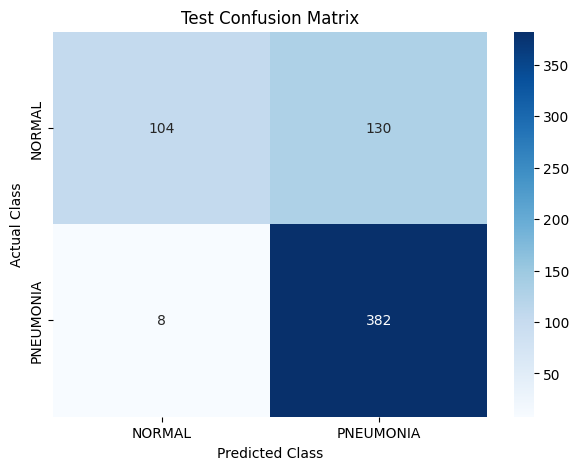


Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.93      0.44      0.60       234
   PNEUMONIA       0.75      0.98      0.85       390

    accuracy                           0.78       624
   macro avg       0.84      0.71      0.72       624
weighted avg       0.81      0.78      0.75       624



In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Generate test predictions
test_predictions = model.predict(test_ds)

# Convert probabilities into class labels
predicted_classes = (
    test_predictions.flatten() >= 0.5
).astype(int)

# Get actual test labels
actual_classes = np.concatenate([
    labels.numpy().flatten()
    for images, labels in test_ds
]).astype(int)

# Create confusion matrix
cm = confusion_matrix(
    actual_classes,
    predicted_classes
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Test Confusion Matrix")
plt.show()

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        actual_classes,
        predicted_classes,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

In [34]:
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Predict on validation data
val_predictions = model.predict(val_ds).flatten()

# Actual validation labels
val_labels = np.concatenate([
    labels.numpy().flatten()
    for images, labels in val_ds
]).astype(int)

# Compare different thresholds
results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (val_predictions >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Balanced Accuracy": balanced_accuracy_score(
            val_labels, predictions
        ),
        "Macro F1": f1_score(
            val_labels, predictions, average="macro"
        )
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.sort_values(
        "Balanced Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 304ms/step


,Threshold,Balanced Accuracy,Macro F1
0,0.15,0.498835,0.472194
1,0.20,0.496888,0.480849
2,0.10,0.495421,0.446739
3,0.25,0.492959,0.481331
4,0.30,0.488478,0.483015
5,0.40,0.488318,0.486761
6,0.35,0.484451,0.480698
7,0.60,0.484228,0.484360
8,0.50,0.483739,0.483676
9,0.45,0.483544,0.483127


In [35]:
import numpy as np

normal_probs = val_predictions[val_labels == 0]
pneumonia_probs = val_predictions[val_labels == 1]

print("NORMAL probability statistics:")
print("Min:", normal_probs.min())
print("Max:", normal_probs.max())
print("Mean:", normal_probs.mean())
print("Median:", np.median(normal_probs))

print("\nPNEUMONIA probability statistics:")
print("Min:", pneumonia_probs.min())
print("Max:", pneumonia_probs.max())
print("Mean:", pneumonia_probs.mean())
print("Median:", np.median(pneumonia_probs))

print("\nValidation AUC:",
      tf.keras.metrics.AUC()(val_labels, val_predictions).numpy())

NORMAL probability statistics:
Min: 0.05363767
Max: 0.9996679
Mean: 0.768721
Median: 0.92583835

PNEUMONIA probability statistics:
Min: 0.034424365
Max: 0.99977666
Mean: 0.7362955
Median: 0.9055164

Validation AUC: 0.46540275


In [36]:
# Confirm class ordering
print("Class names:", val_ds.class_names if hasattr(val_ds, "class_names") else "Attribute unavailable")

# Display a few actual labels and predictions
for images, labels in val_ds.take(1):
    batch_predictions = model.predict(images, verbose=0).flatten()

    print("\nFirst 15 actual labels:")
    print(labels.numpy().flatten()[:15].astype(int))

    print("\nFirst 15 prediction probabilities:")
    print(np.round(batch_predictions[:15], 3))

Class names: Attribute unavailable

First 15 actual labels:
[1 1 1 1 0 1 1 1 1 1 1 1 1 1 1]

First 15 prediction probabilities:
[0.962 0.979 0.953 0.995 0.454 0.955 0.702 0.993 0.936 0.941 0.965 0.96
 0.923 0.995 0.885]


In [37]:
from sklearn.metrics import roc_auc_score, confusion_matrix
import numpy as np

# Collect predictions and labels together in one pass
all_labels = []
all_predictions = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0).flatten()

    all_labels.extend(labels.numpy().flatten())
    all_predictions.extend(predictions)

all_labels = np.array(all_labels).astype(int)
all_predictions = np.array(all_predictions)

# Calculate metrics independently
print("Validation image count:", len(all_labels))
print("NORMAL labels:", np.sum(all_labels == 0))
print("PNEUMONIA labels:", np.sum(all_labels == 1))

print("\nScikit-learn AUC:",
      roc_auc_score(all_labels, all_predictions))

print("\nConfusion matrix at threshold 0.5:")
print(confusion_matrix(
    all_labels,
    (all_predictions >= 0.5).astype(int)
))

Validation image count: 782
NORMAL labels: 190
PNEUMONIA labels: 592

Scikit-learn AUC: 0.9701813655761024

Confusion matrix at threshold 0.5:
[[165  25]
 [ 23 569]]


In [38]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/train",
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Validation dataset recreated without shuffling.")

Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Validation dataset recreated without shuffling.


In [39]:
val_results = model.evaluate(val_ds, return_dict=True)

print("\nValidation Results:")
for metric, value in val_results.items():
    print(f"{metric}: {value:.4f}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 164ms/step - accuracy: 0.9463 - auc: 0.0000e+00 - loss: 0.1358 - precision: 1.0000 - recall: 0.9463

Validation Results:
accuracy: 0.9463
auc: 0.0000
loss: 0.1358
precision: 1.0000
recall: 0.9463


In [40]:
test_results = model.evaluate(test_ds, return_dict=True)

print("\nTest Results:")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 212ms/step - accuracy: 0.7788 - auc: 0.9365 - loss: 0.4110 - precision: 0.7461 - recall: 0.9795

Test Results:
accuracy: 0.7788
auc: 0.9365
loss: 0.4110
precision: 0.7461
recall: 0.9795


In [41]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import numpy as np

def get_predictions(dataset):
    actual = []
    predicted = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0).flatten()
        actual.extend(labels.numpy().flatten())
        predicted.extend(probabilities)

    return np.array(actual).astype(int), np.array(predicted)

# Collect both datasets
val_actual, val_probs = get_predictions(val_ds)
test_actual, test_probs = get_predictions(test_ds)

# Validation results
print("VALIDATION CONFUSION MATRIX")
print(confusion_matrix(
    val_actual,
    (val_probs >= 0.5).astype(int)
))

print("\nTEST CONFUSION MATRIX")
print(confusion_matrix(
    test_actual,
    (test_probs >= 0.5).astype(int)
))

print("\nTEST CLASSIFICATION REPORT")
print(classification_report(
    test_actual,
    (test_probs >= 0.5).astype(int),
    target_names=["NORMAL", "PNEUMONIA"]
))

print("Validation AUC:", roc_auc_score(val_actual, val_probs))
print("Test AUC:", roc_auc_score(test_actual, test_probs))

VALIDATION CONFUSION MATRIX
[[  0   0]
 [ 42 740]]

TEST CONFUSION MATRIX
[[104 130]
 [  8 382]]

TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.93      0.44      0.60       234
   PNEUMONIA       0.75      0.98      0.85       390

    accuracy                           0.78       624
   macro avg       0.84      0.71      0.72       624
weighted avg       0.81      0.78      0.75       624

Validation AUC: nan
Test AUC: 0.9364672364672364


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


In [42]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_PATH}/train",
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=True
)

val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Validation dataset corrected!")

Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Validation dataset corrected!


In [43]:
val_labels_check = np.concatenate([
    labels.numpy().flatten()
    for images, labels in val_ds
]).astype(int)

print("NORMAL:", np.sum(val_labels_check == 0))
print("PNEUMONIA:", np.sum(val_labels_check == 1))
print("Total:", len(val_labels_check))

NORMAL: 190
PNEUMONIA: 592
Total: 782


In [44]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import numpy as np

val_actual = []
val_probs = []

for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0).flatten()

    val_actual.extend(labels.numpy().flatten())
    val_probs.extend(probabilities)

val_actual = np.array(val_actual).astype(int)
val_probs = np.array(val_probs)

val_predicted = (val_probs >= 0.5).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(val_actual, val_predicted), 4))

print("Validation AUC:",
      round(roc_auc_score(val_actual, val_probs), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(val_actual, val_predicted))

print("\nClassification Report:")
print(classification_report(
    val_actual,
    val_predicted,
    target_names=["NORMAL", "PNEUMONIA"]
))

Validation Accuracy: 0.9386
Validation AUC: 0.9702

Confusion Matrix:
[[165  25]
 [ 23 569]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.88      0.87      0.87       190
   PNEUMONIA       0.96      0.96      0.96       592

    accuracy                           0.94       782
   macro avg       0.92      0.91      0.92       782
weighted avg       0.94      0.94      0.94       782



In [45]:
# Unfreeze the base model
base_model.trainable = True

# Keep earlier layers frozen; fine-tune only the final 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a very low learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Fine-tuning model prepared!")
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Fine-tuning model prepared!
Trainable layers: 30


In [46]:
fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=[fine_tune_early_stopping]
)

Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 43s 218ms/step - accuracy: 0.9014 - auc: 0.9601 - loss: 0.2745 - precision: 0.9441 - recall: 0.9214 - val_accuracy: 0.9463 - val_auc: 0.9764 - val_loss: 0.1690 - val_precision: 0.9493 - val_recall: 0.9814
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 32s 226ms/step - accuracy: 0.9231 - auc: 0.9800 - loss: 0.1861 - precision: 0.9795 - recall: 0.9153 - val_accuracy: 0.9527 - val_auc: 0.9806 - val_loss: 0.1467 - val_precision: 0.9587 - val_recall: 0.9797
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 41s 223ms/step - accuracy: 0.9355 - auc: 0.9868 - loss: 0.1513 - precision: 0.9845 - recall: 0.9275 - val_accuracy: 0.9578 - val_auc: 0.9830 - val_loss: 0.1299 - val_precision: 0.9761 - val_recall: 0.9679
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 31s 221ms/step - accuracy: 0.9441 - auc: 0.9905 - loss: 0.1310 - precision: 0.9859 - recall: 0.9379 - val_accuracy: 0.9501 - val_auc: 0.9846 - val_loss: 0.1307 - val_precision: 0.9842 - val_recall: 0.9493
Epoch 5/5
139/139 ━━━━━━

In [47]:
fine_tuned_test_results = model.evaluate(
    test_ds,
    return_dict=True
)

print("\nFine-Tuned Model Test Results")

for metric, value in fine_tuned_test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 215ms/step - accuracy: 0.8317 - auc: 0.9575 - loss: 0.3765 - precision: 0.7987 - recall: 0.9769

Fine-Tuned Model Test Results
accuracy: 0.8317
auc: 0.9575
loss: 0.3765
precision: 0.7987
recall: 0.9769


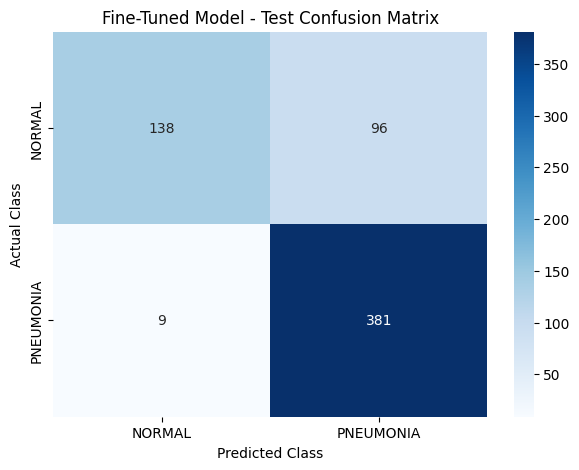

Final Test Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.59      0.72       234
   PNEUMONIA       0.80      0.98      0.88       390

    accuracy                           0.83       624
   macro avg       0.87      0.78      0.80       624
weighted avg       0.85      0.83      0.82       624



In [48]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

test_actual = []
test_probabilities = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).flatten()

    test_actual.extend(labels.numpy().flatten())
    test_probabilities.extend(predictions)

test_actual = np.array(test_actual).astype(int)
test_probabilities = np.array(test_probabilities)

test_predicted = (test_probabilities >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(test_actual, test_predicted)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Fine-Tuned Model - Test Confusion Matrix")
plt.show()

# Classification report
print("Final Test Classification Report:")
print(classification_report(
    test_actual,
    test_predicted,
    target_names=["NORMAL", "PNEUMONIA"]
))

In [49]:
# Save the fine-tuned model
MODEL_PATH = "/content/chest_xray_mobilenetv2.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: /content/chest_xray_mobilenetv2.keras


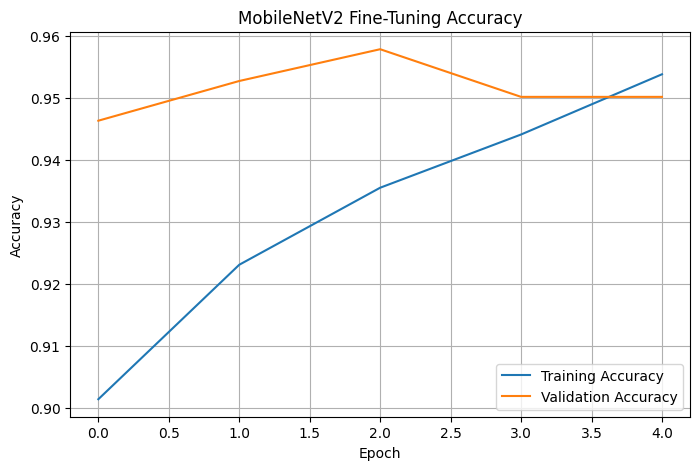

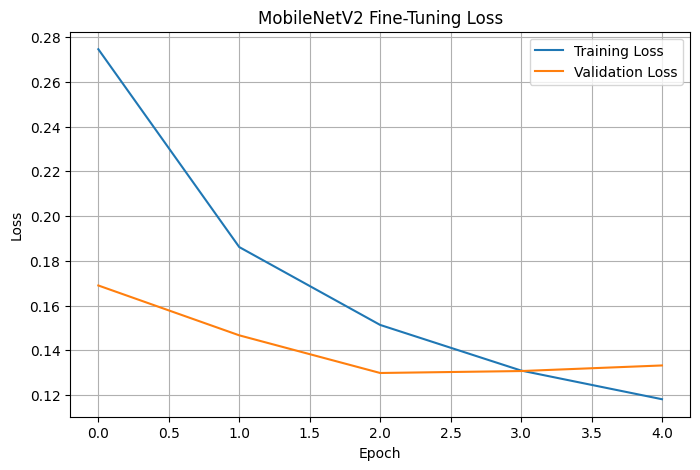

In [50]:
import matplotlib.pyplot as plt

# Fine-tuning accuracy
plt.figure(figsize=(8, 5))
plt.plot(fine_tune_history.history["accuracy"], label="Training Accuracy")
plt.plot(fine_tune_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Fine-tuning loss
plt.figure(figsize=(8, 5))
plt.plot(fine_tune_history.history["loss"], label="Training Loss")
plt.plot(fine_tune_history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [51]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array

def predict_chest_xray(image_path):
    # Load and resize image
    image = load_img(
        image_path,
        target_size=(224, 224),
        color_mode="rgb"
    )

    # Convert image into an array
    image_array = img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    probability = model.predict(image_array, verbose=0)[0][0]

    # Classify
    if probability >= 0.5:
        prediction = "PNEUMONIA"
        confidence = probability * 100
    else:
        prediction = "NORMAL"
        confidence = (1 - probability) * 100

    print("Prediction:", prediction)
    print("Model confidence:", round(float(confidence), 2), "%")

    return prediction

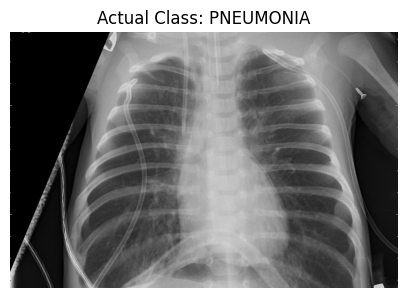

Prediction: PNEUMONIA
Model confidence: 98.76 %


'PNEUMONIA'

In [53]:
import os
import random
import matplotlib.pyplot as plt

# Select a sample image from the test dataset
sample_class = "PNEUMONIA"  # Change to "PNEUMONIA" to test the other class

sample_folder = os.path.join(
    DATASET_PATH, "test", sample_class
)

sample_image = random.choice(os.listdir(sample_folder))
sample_path = os.path.join(sample_folder, sample_image)

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(plt.imread(sample_path), cmap="gray")
plt.title(f"Actual Class: {sample_class}")
plt.axis("off")
plt.show()

# Run prediction
predict_chest_xray(sample_path)

In [54]:
print("=" * 60)
print("MEDICAL IMAGE CLASSIFICATION USING TRANSFER LEARNING")
print("=" * 60)

print("\nPROJECT OVERVIEW")
print("Task: Binary classification of chest X-ray images")
print("Classes: NORMAL and PNEUMONIA")
print("Dataset: Chest X-Ray Images (Pneumonia) - Kaggle")
print("Architecture: MobileNetV2")
print("Approach: Transfer Learning + Fine-Tuning")

print("\nDATASET")
print("Training images: 4434")
print("Validation images: 782")
print("Testing images: 624")
print("Image size: 224 x 224")

print("\nFINAL TEST PERFORMANCE")
print(f"Accuracy:  {fine_tuned_test_results['accuracy'] * 100:.2f}%")
print(f"AUC:       {fine_tuned_test_results['auc'] * 100:.2f}%")
print(f"Precision: {fine_tuned_test_results['precision'] * 100:.2f}%")
print(f"Recall:    {fine_tuned_test_results['recall'] * 100:.2f}%")

print("\nMODEL")
print("Saved model:", MODEL_PATH)

print("\nCONCLUSION")
print("MobileNetV2 transfer learning successfully classified")
print("chest X-ray images into NORMAL and PNEUMONIA classes.")
print("This is an educational prototype, not a clinical diagnostic tool.")

print("=" * 60)

MEDICAL IMAGE CLASSIFICATION USING TRANSFER LEARNING

PROJECT OVERVIEW
Task: Binary classification of chest X-ray images
Classes: NORMAL and PNEUMONIA
Dataset: Chest X-Ray Images (Pneumonia) - Kaggle
Architecture: MobileNetV2
Approach: Transfer Learning + Fine-Tuning

DATASET
Training images: 4434
Validation images: 782
Testing images: 624
Image size: 224 x 224

FINAL TEST PERFORMANCE
Accuracy:  83.17%
AUC:       95.75%
Precision: 79.87%
Recall:    97.69%

MODEL
Saved model: /content/chest_xray_mobilenetv2.keras

CONCLUSION
MobileNetV2 transfer learning successfully classified
chest X-ray images into NORMAL and PNEUMONIA classes.
This is an educational prototype, not a clinical diagnostic tool.
